<a href="https://colab.research.google.com/github/abhi07dev/DBMS_PRAC_1/blob/main/market_analysisipynb_ML_Prac_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import io
import os
import re
import sys
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
from IPython.display import Image, display
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import silhouette_score, r2_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
TRADING_DAYS = 252
MONTH_END = "ME" if tuple(map(int, pd.__version__.split(".")[:2])) >= (2, 2) else "M"
YEAR_END = "YE" if MONTH_END == "ME" else "Y"

In [14]:
# ---- CHANGE THESE ----
SOURCE = "/content/Data(1).zip"          # path to the ZIP (or a folder of CSVs)
OUT = Path("results")        # all charts/tables are saved here
START, END = "2000-01-01", "2020-12-31"
OUT.mkdir(exist_ok=True)
def show(name): display(Image(filename=str(OUT / name)))

In [15]:
DATE_KEYS = ("date", "timestamp", "time", "day")
CLOSE_KEYS = ("adj close", "adj_close", "adjclose", "close price", "closing price",
              "close", "last", "price")
VOL_KEYS = ("volume", "vol", "shares traded", "total traded quantity")

In [16]:
def _pick(columns, keys):
    low = {c.lower().strip(): c for c in columns}
    for k in keys:                      # priority order
        if k in low:
            return low[k]
    for k in keys:                      # fallback: substring match
        for lc, c in low.items():
            if k in lc:
                return c
    return None

In [17]:
def parse_csv(raw, name):
    """Return (symbol, DataFrame[close, volume] indexed by date) or raise."""
    df = pd.read_csv(raw, low_memory=False)
    dcol, ccol, vcol = _pick(df.columns, DATE_KEYS), _pick(df.columns, CLOSE_KEYS), _pick(df.columns, VOL_KEYS)
    if dcol is None or ccol is None:
        raise ValueError(f"no date/close column in {list(df.columns)[:8]}")
    out = pd.DataFrame({
        "close": pd.to_numeric(df[ccol].astype(str).str.replace(",", ""), errors="coerce"),
        "volume": pd.to_numeric(df[vcol], errors="coerce") if vcol else np.nan,
    })
    # try ISO first; fall back to day-first (common in Indian exports)
    d = pd.to_datetime(df[dcol], errors="coerce")
    if d.isna().mean() > 0.5:
        d = pd.to_datetime(df[dcol], errors="coerce", dayfirst=True)
    out.index = d
    out = out[out.index.notna() & (out["close"] > 0)]
    out = out[~out.index.duplicated(keep="last")].sort_index()
    if len(out) < 60:
        raise ValueError(f"only {len(out)} usable rows")
    return Path(name).stem.upper(), out

In [18]:
def iter_csvs(src):
    """Yield (name, file-like) from a zip (incl. nested folders) or a directory."""
    p = Path(src)
    if p.is_dir():
        for f in sorted(p.rglob("*.csv")):
            yield f.name, str(f)
    else:
        with zipfile.ZipFile(p) as z:
            for n in sorted(z.namelist()):
                if n.lower().endswith(".csv") and "__MACOSX" not in n and not Path(n).name.startswith("."):
                    yield n, io.BytesIO(z.read(n))

In [19]:
def load_all(src, start="2000-01-01", end="2020-12-31"):
    closes, volumes, bad = {}, {}, []
    for i, (name, raw) in enumerate(iter_csvs(src), 1):
        try:
            sym, df = parse_csv(raw, name)
            df = df.loc[start:end]
            if len(df) < 60:
                raise ValueError("fewer than 60 rows in 2000-2020 window")
            if sym in closes:                       # duplicate names across folders
                sym = f"{sym}_{i}"
            closes[sym], volumes[sym] = df["close"], df["volume"]
        except Exception as e:
            bad.append((name, str(e)))
        if i % 100 == 0:
            print(f"  ...read {i} files", flush=True)
    if not closes:
        sys.exit("No usable CSV files found.")
    close = pd.DataFrame(closes).sort_index()
    volume = pd.DataFrame(volumes).reindex(close.index)
    print(f"Loaded {close.shape[1]} series, {close.shape[0]} dates "
          f"({close.index.min().date()} -> {close.index.max().date()}); skipped {len(bad)} files.")
    return close, volume, bad

In [20]:
def clean_returns(close, max_abs=0.5):
    """Daily simple returns. Gaps are NOT forward-filled (a missing day != 0% move);
    absurd one-day moves (splits/bad ticks) are dropped rather than trusted."""
    r = close.pct_change(fill_method=None)
    r = r.where(r.abs() <= max_abs)
    return r

In [21]:
import os

# Check if the source exists and is a valid file/directory before loading
if not os.path.exists(SOURCE):
    print(f"[ERROR] The specified SOURCE path does not exist: '{SOURCE}'")
    print("Please upload your ZIP file to Google Colab and update the SOURCE variable if necessary.")
else:
    try:
        close, volume, bad = load_all(SOURCE, START, END)
        if bad:
            pd.DataFrame(bad, columns=["file", "reason"]).to_csv(OUT / "skipped_files.csv", index=False)
            display(pd.DataFrame(bad, columns=["file", "reason"]).head(10))
        ret = clean_returns(close)
        display(close.iloc[:, :5].tail())
    except zipfile.BadZipFile:
        print(f"[ERROR] '{SOURCE}' is not a valid ZIP file or is corrupted.")
        print("Please verify that the file uploaded fully and is a valid ZIP archive.")

  ...read 100 files
  ...read 200 files
  ...read 300 files
  ...read 400 files
  ...read 500 files
  ...read 600 files
  ...read 700 files
  ...read 800 files
  ...read 900 files
  ...read 1000 files
  ...read 1100 files
  ...read 1200 files
  ...read 1300 files
  ...read 1400 files
  ...read 1500 files
  ...read 1600 files
  ...read 1700 files
  ...read 1800 files
  ...read 1900 files
  ...read 2000 files
  ...read 2100 files
  ...read 2200 files
  ...read 2300 files
  ...read 2400 files
  ...read 2500 files
  ...read 2600 files
  ...read 2700 files
  ...read 2800 files
  ...read 2900 files
  ...read 3000 files
  ...read 3100 files
  ...read 3200 files
  ...read 3300 files
  ...read 3400 files
  ...read 3500 files
  ...read 3600 files
  ...read 3700 files
  ...read 3800 files
  ...read 3900 files
  ...read 4000 files
  ...read 4100 files
  ...read 4200 files
  ...read 4300 files
  ...read 4400 files
  ...read 4500 files
  ...read 4600 files
  ...read 4700 files
  ...read 4800 files
 

,20MICRONS.BO,20MICRONS.NS,21STCENMGM.BO,21STCENMGM.NS,3IINFOTECH.BO
Date,,,,,
2020-06-01,27.100000,26.900000,11.01,10.8,1.66
2020-06-02,27.500000,27.500000,11.22,11.0,1.71
2020-06-03,29.100000,28.850000,11.44,10.8,1.75
2020-06-04,28.549999,28.299999,11.65,10.6,1.81
2020-06-05,29.150000,29.500000,11.65,10.7,1.99


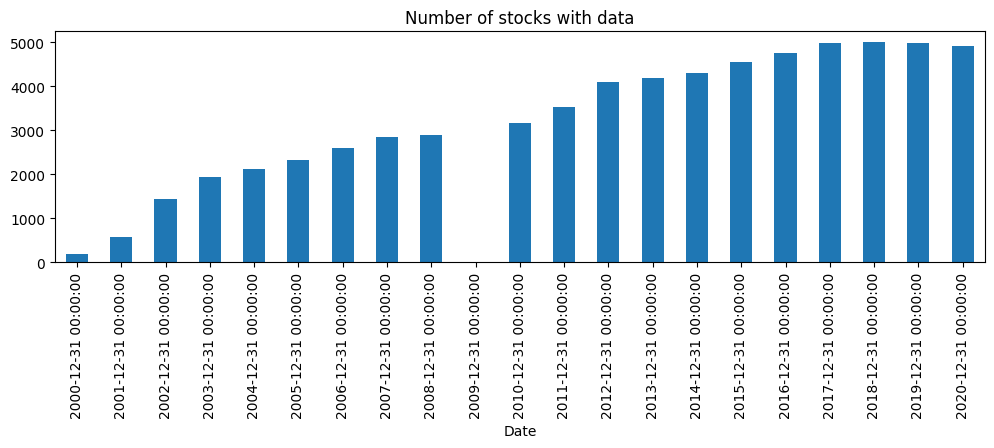

In [22]:
# Data quality check: how many stocks are live over time? (the universe changes a lot 2000-2020)
close.notna().sum(axis=1).resample("YE" if MONTH_END == "ME" else "Y").last().plot(kind="bar", figsize=(12, 3), title="Number of stocks with data")
plt.show()

In [23]:
def market_analysis(ret, out):
    mkt = ret.mean(axis=1, skipna=True).dropna()          # equal-weighted market return
    breadth = ret.notna().sum(axis=1).loc[mkt.index]
    idx = (1 + mkt).cumprod() * 100
    dd = idx / idx.cummax() - 1
    vol21 = mkt.rolling(21).std() * np.sqrt(TRADING_DAYS)

    # regimes: bear = drawdown worse than -20% from peak; else bull
    regime = np.where(dd <= -0.20, "Bear", "Bull/Normal")

    yearly = idx.resample(YEAR_END).last().pct_change()
    yearly.iloc[0] = idx.resample(YEAR_END).last().iloc[0] / 100 - 1
    yr = pd.DataFrame({"market_return_%": (yearly * 100).round(1),
                       "stocks_up_%": (lambda yret, has: yret.gt(0).where(has).mean(axis=1).mul(100).round(1))(
                           ret.add(1).resample(YEAR_END).prod().sub(1),
                           ret.notna().resample(YEAR_END).sum().gt(100))})
    yr.index = yr.index.year
    yr.to_csv(out / "market_yearly_returns.csv")

    fig, ax = plt.subplots(4, 1, figsize=(12, 14), sharex=True)
    ax[0].plot(idx); ax[0].set_yscale("log"); ax[0].set_title("Equal-weighted market index (base 100, log scale)")
    bear = pd.Series(regime == "Bear", index=idx.index)
    ax[0].fill_between(idx.index, idx.min(), idx.max(), where=bear, color="red", alpha=0.12, label="Bear (DD<-20%)")
    ax[0].legend()
    ax[1].plot(mkt, lw=0.4); ax[1].set_title("Daily market return")
    ax[2].plot(vol21, color="tab:red"); ax[2].set_title("21-day annualised volatility")
    ax[3].fill_between(dd.index, dd, 0, color="grey"); ax[3].set_title("Drawdown")
    plt.tight_layout(); plt.savefig(out / "01_market_overview.png", dpi=120); plt.close()

    colors = ["tab:green" if v >= 0 else "tab:red" for v in yr["market_return_%"]]
    plt.figure(figsize=(12, 4)); plt.bar(yr.index.astype(str), yr["market_return_%"], color=colors)
    plt.title("Calendar-year market return (%)"); plt.xticks(rotation=60); plt.tight_layout()
    plt.savefig(out / "02_yearly_returns.png", dpi=120); plt.close()

    # bear-market episodes
    ep, start = [], None
    for t, is_bear in bear.items():
        if is_bear and start is None: start = t
        if (not is_bear) and start is not None:
            ep.append((start, t)); start = None
    summary = {
        "annualised_return": mkt.mean() * TRADING_DAYS,
        "annualised_vol": mkt.std() * np.sqrt(TRADING_DAYS),
        "max_drawdown": dd.min(), "max_drawdown_date": str(dd.idxmin().date()),
        "pct_up_days": (mkt > 0).mean(),
        "worst_day": f"{mkt.min():.2%} on {mkt.idxmin().date()}",
        "best_day": f"{mkt.max():.2%} on {mkt.idxmax().date()}",
        "bear_episodes": [(str(a.date()), str(b.date())) for a, b in ep],
    }
    print("\n=== MARKET UPS & DOWNS ===")
    print(yr.to_string())
    for k, v in summary.items():
        print(f"{k}: {v:.2%}" if isinstance(v, float) else f"{k}: {v}")
    return mkt, summary


=== MARKET UPS & DOWNS ===
      market_return_% stocks_up_%
Date                             
2000            -14.0   23.786408
2001              5.1   36.947791
2002            104.3   55.498282
2003            250.9   91.555556
2004            108.2   82.099738
2005             86.4   74.532502
2006             29.7   53.448988
2007            101.2   86.495413
2008            -60.4    2.986612
2009            117.3   90.053583
2010             30.2   64.475743
2011            -29.5   15.233881
2012             35.0   66.510365
2013             -7.7   29.424565
2014             65.3   74.522743
2015             28.1   53.620573
2016             15.0   53.681047
2017             40.0   72.353903
2018            -23.5   22.481548
2019            -20.5   24.364364
2020             -9.2         0.0
annualised_return: 25.03%
annualised_vol: 20.34%
max_drawdown: -68.75%
max_drawdown_date: 2009-03-09
pct_up_days: 55.21%
worst_day: -11.19% on 2002-10-03
best_day: 10.67% on 2002-10-02
bear_

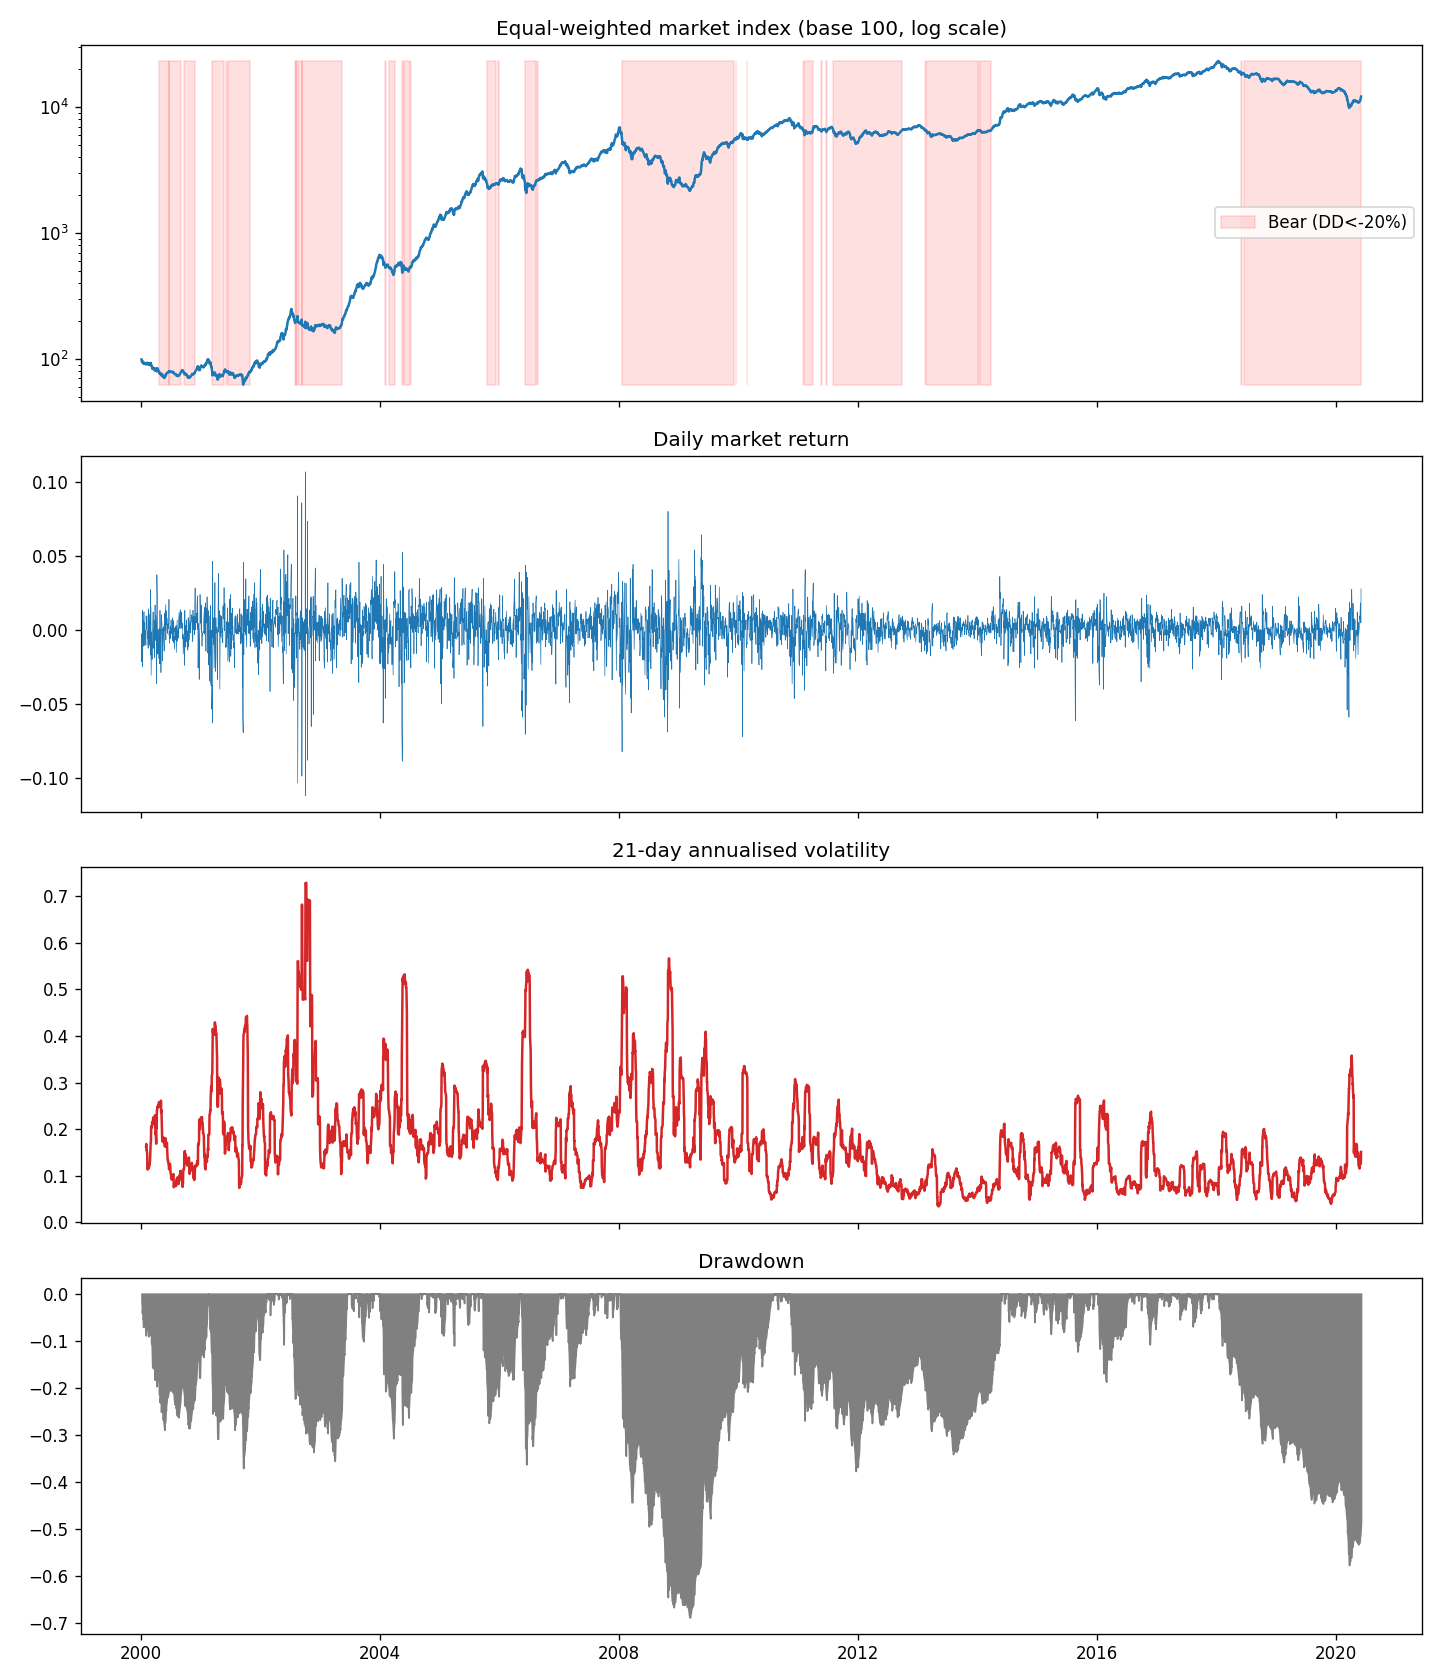

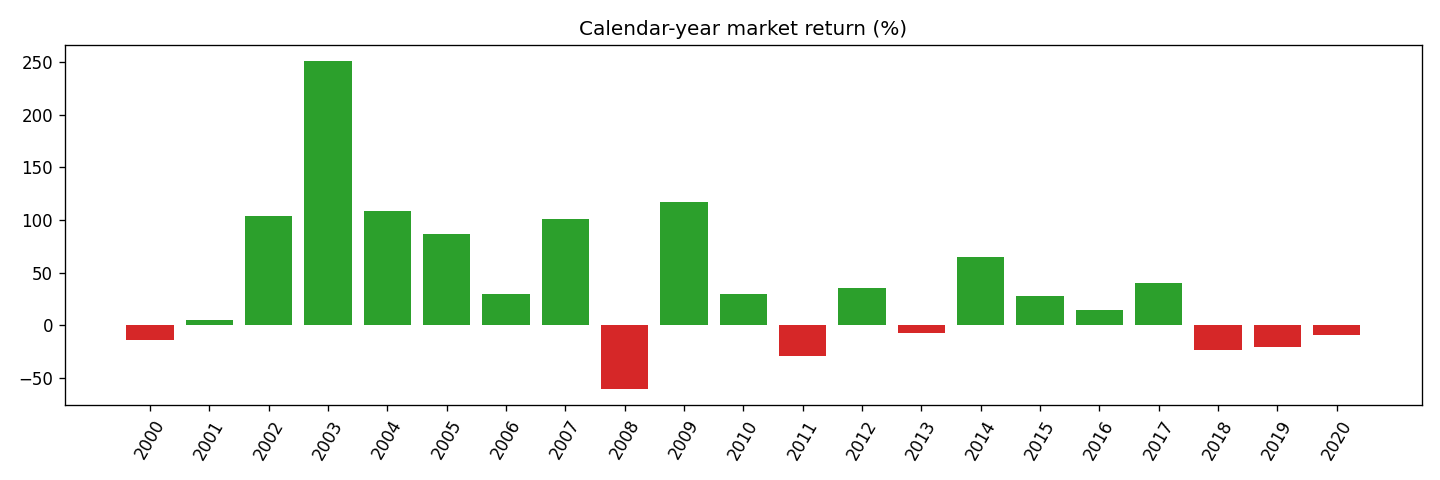

In [24]:
mkt, summary = market_analysis(ret, OUT)
show("01_market_overview.png"); show("02_yearly_returns.png")

In [25]:
def stock_features(close, volume, ret, mkt, min_years=2):
    rows = {}
    mvar = mkt.var()
    for s in close.columns:
        r = ret[s].dropna()
        if len(r) < TRADING_DAYS * min_years:
            continue
        c = close[s].dropna()
        dd = (c / c.cummax() - 1).min()
        both = pd.concat([r, mkt], axis=1, join="inner").dropna()
        beta = both.iloc[:, 0].cov(both.iloc[:, 1]) / mvar if len(both) > 60 else np.nan
        v = volume[s].dropna()
        rows[s] = {
            "ann_return": r.mean() * TRADING_DAYS,
            "ann_vol": r.std() * np.sqrt(TRADING_DAYS),
            "sharpe": (r.mean() / r.std()) * np.sqrt(TRADING_DAYS) if r.std() > 0 else np.nan,
            "max_drawdown": dd,
            "skew": r.skew(), "kurtosis": r.kurt(),
            "beta": beta,
            "log_avg_volume": np.log1p(v.mean()) if len(v) else np.nan,
            "years_listed": len(r) / TRADING_DAYS,
        }
    feats = pd.DataFrame(rows).T
    return feats.replace([np.inf, -np.inf], np.nan)

In [26]:
def clustering(feats, out, k_range=range(2, 11)):
    use = feats.drop(columns=["years_listed"]).copy()
    use = use.loc[:, use.notna().mean() > 0.8]            # drop columns that are mostly missing (e.g. volume)
    use = use.fillna(use.median())
    # winsorise heavy tails so a handful of outliers don't form their own clusters
    lo, hi = use.quantile(0.01), use.quantile(0.99)
    X = StandardScaler().fit_transform(use.clip(lo, hi, axis=1))

    inertia, sil = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inertia.append(km.inertia_)
        sil.append(silhouette_score(X, km.labels_, sample_size=min(2000, len(X)), random_state=42))
    best_k = list(k_range)[int(np.argmax(sil))]

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(list(k_range), inertia, "bx-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
    ax[1].plot(list(k_range), sil, "go-"); ax[1].axvline(best_k, ls="--", c="k")
    ax[1].set_title(f"Silhouette score (best k = {best_k})"); ax[1].set_xlabel("k")
    plt.tight_layout(); plt.savefig(out / "03_elbow_silhouette.png", dpi=120); plt.close()

    km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
    feats = feats.copy(); feats["cluster"] = km.labels_

    pca = PCA(n_components=2).fit(X); P = pca.transform(X)
    plt.figure(figsize=(10, 7))
    sc = plt.scatter(P[:, 0], P[:, 1], c=km.labels_, cmap="tab10", s=14, alpha=0.8)
    cen = pca.transform(km.cluster_centers_)
    plt.scatter(cen[:, 0], cen[:, 1], c="black", marker="x", s=250)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    plt.title(f"K-Means clusters (k={best_k}) in PCA space"); plt.legend(*sc.legend_elements(), title="cluster")
    plt.tight_layout(); plt.savefig(out / "04_kmeans_pca.png", dpi=120); plt.close()

    # hierarchical (Ward) on a sample so the dendrogram is readable
    samp = np.random.default_rng(0).choice(len(X), size=min(60, len(X)), replace=False)
    Z = linkage(X[samp], method="ward")
    plt.figure(figsize=(14, 5)); dendrogram(Z, labels=feats.index[samp].tolist(), leaf_rotation=90, leaf_font_size=7)
    plt.title("Hierarchical clustering (Ward) - random sample of 60 stocks"); plt.tight_layout()
    plt.savefig(out / "05_dendrogram.png", dpi=120); plt.close()

    profile = feats.groupby("cluster").agg(n_stocks=("ann_return", "size"),
                                           **{c: (c, "mean") for c in use.columns})
    profile.round(3).to_csv(out / "cluster_profiles.csv")
    feats.round(4).to_csv(out / "stock_features_with_clusters.csv")
    print(f"\n=== CLUSTERING ===\nBest k by silhouette: {best_k}  (check the elbow plot too)")
    print(profile.round(3).to_string())
    return feats

In [27]:
feats = stock_features(close, volume, ret, mkt)
print(len(feats), "stocks with enough history")
feats.describe().round(3)

5023 stocks with enough history


,ann_return,ann_vol,sharpe,max_drawdown,skew,kurtosis,beta,log_avg_volume,years_listed
count,5023.000,5023.000,4991.000,5023.000,5023.000,5023.000,5023.000,5023.000,5023.000
mean,0.135,0.521,0.249,-0.828,0.698,16.216,0.632,9.769,11.592
std,0.272,0.175,0.564,0.189,2.344,76.738,0.417,2.966,4.953
min,-1.585,0.000,-3.872,-1.000,-43.081,-1.368,-0.144,0.000,2.000
25%,0.000,0.423,0.002,-0.957,0.303,3.909,0.265,8.378,7.365
50%,0.163,0.533,0.328,-0.883,0.647,5.835,0.673,10.067,12.393
75%,0.304,0.626,0.581,-0.774,0.963,9.405,0.967,11.624,16.232
max,1.088,1.674,3.211,0.000,43.081,1856.000,1.890,17.710,19.563



=== CLUSTERING ===
Best k by silhouette: 2  (check the elbow plot too)
         n_stocks  ann_return  ann_vol  sharpe  max_drawdown   skew  kurtosis   beta  log_avg_volume
cluster                                                                                             
0            3625       0.221    0.581   0.394        -0.868  0.758     7.570  0.814          10.752
1            1398      -0.088    0.367  -0.136        -0.722  0.540    38.635  0.160           7.219


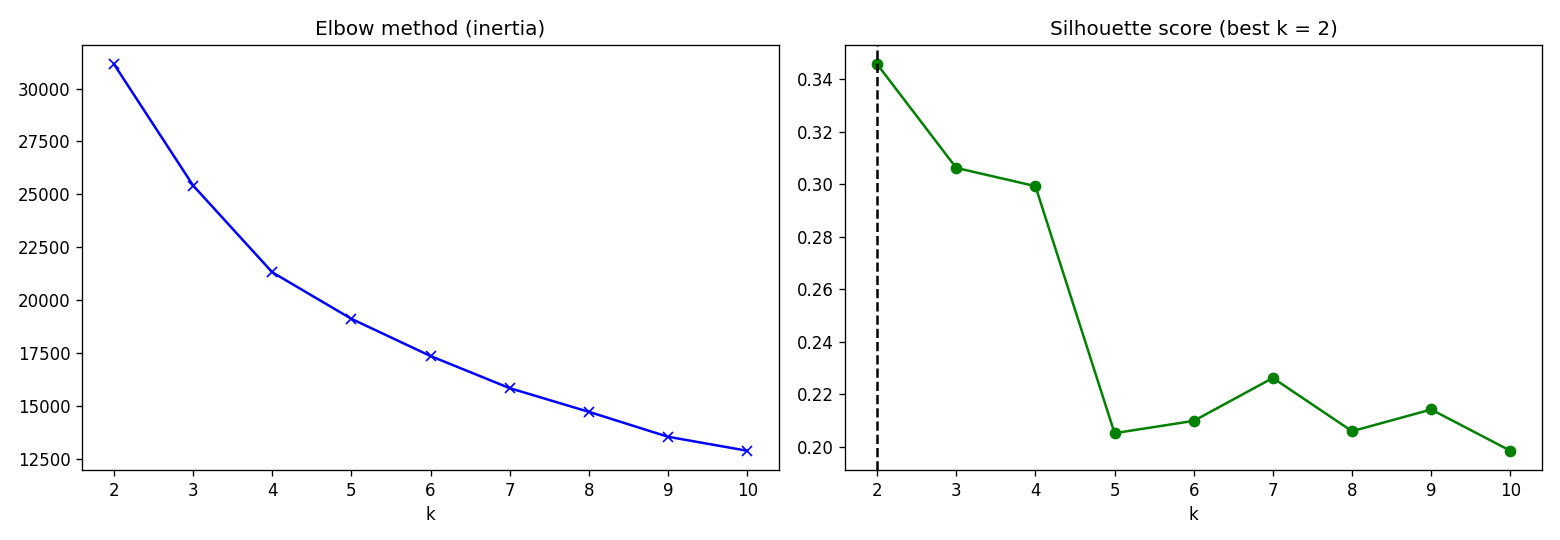

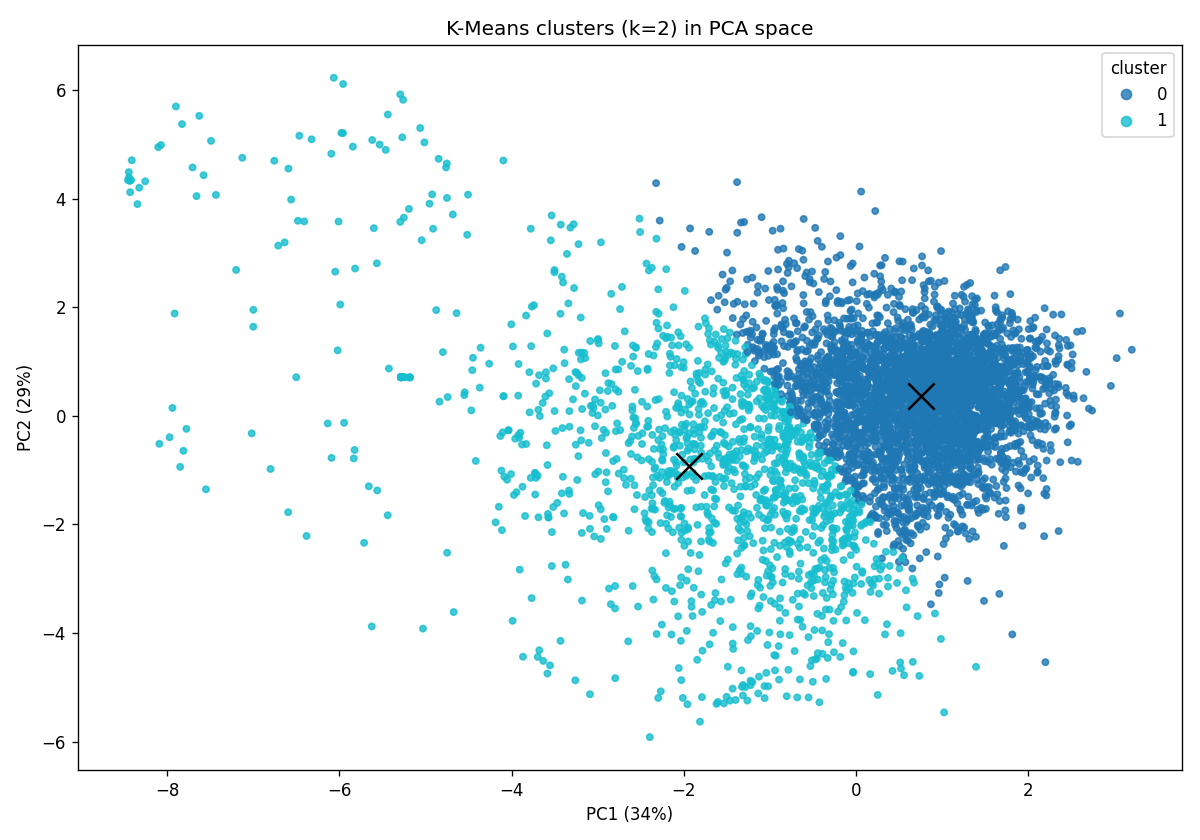

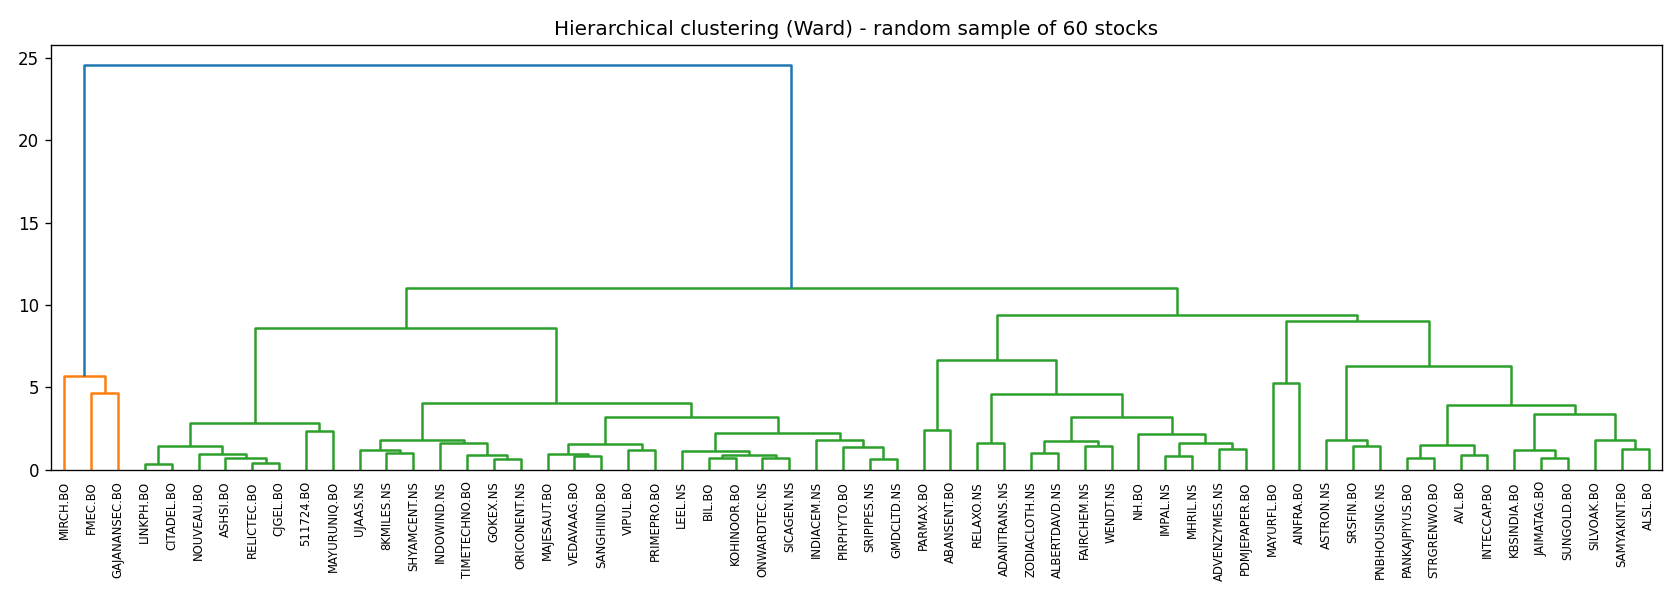

In [28]:
feats = clustering(feats, OUT)
show("03_elbow_silhouette.png"); show("04_kmeans_pca.png"); show("05_dendrogram.png")

In [29]:
def build_panel(close, volume):
    m = close.resample(MONTH_END).last()
    daily = close.pct_change(fill_method=None).where(lambda x: x.abs() <= 0.5)
    vol_m = daily.rolling(63, min_periods=40).std().resample(MONTH_END).last()
    feats = {
        "mom_1m": m.pct_change(1, fill_method=None),
        "mom_3m": m.pct_change(3, fill_method=None),
        "mom_6m": m.pct_change(6, fill_method=None),
        "mom_12m_ex1": m.shift(1).pct_change(11, fill_method=None),
        "vol_3m": vol_m,
        "drawdown_12m": m / m.rolling(12, min_periods=6).max() - 1,
    }
    target = m.pct_change(1, fill_method=None).shift(-1)
    cap = lambda df: df.clip(-0.9, 2.0)                      # tame split/outlier artefacts
    panel = pd.concat({k: cap(v) if k != "vol_3m" else v for k, v in feats.items()}, axis=1)
    panel = panel.stack(future_stack=True) if hasattr(pd.DataFrame, "stack") and pd.__version__ >= "2.1" else panel.stack(dropna=False)
    panel["target"] = cap(target).stack(future_stack=True) if pd.__version__ >= "2.1" else cap(target).stack(dropna=False)
    panel.index.names = ["date", "symbol"]
    panel = panel.dropna()
    # cross-sectional z-score per month => model learns relative, not absolute, signals
    cols = [c for c in panel.columns if c != "target"]
    panel[cols] = panel.groupby("date")[cols].transform(lambda x: (x - x.mean()) / (x.std() + 1e-9))
    return panel, cols

In [30]:
def prediction(close, volume, mkt, out, split_year=2015):
    panel, cols = build_panel(close, volume)
    dates = panel.index.get_level_values("date")
    train, test = panel[dates.year < split_year - 0], panel[dates.year >= split_year]
    # 1-month gap (target uses next month) already handled by shift; drop last train month to be safe
    train = train[train.index.get_level_values("date") < train.index.get_level_values("date").max()]
    if len(train) < 1000 or len(test) < 500:
        print("Not enough data for the prediction part; skipped."); return

    models = {
        "Ridge": Ridge(alpha=50),
        "GradientBoosting": HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=200,
                                                          min_samples_leaf=200, random_state=0),
    }
    res, preds = [], {}
    base = np.full(len(test), train["target"].mean())
    for name, mdl in models.items():
        mdl.fit(train[cols], train["target"])
        p = mdl.predict(test[cols]); preds[name] = p
        t = test.assign(pred=p)
        ic = t.groupby("date").apply(lambda g: spearmanr(g["pred"], g["target"])[0]).dropna()
        dec = t.groupby("date", group_keys=False).apply(
            lambda g: g.assign(d=pd.qcut(g["pred"].rank(method="first"), 10, labels=False)))
        spread = dec.groupby(["date", "d"])["target"].mean().unstack()
        ls = (spread[9] - spread[0]).dropna()
        res.append({"model": name,
                    "R2_out_of_sample": r2_score(test["target"], p),
                    "R2_baseline(train mean)": r2_score(test["target"], base),
                    "directional_acc_%": 100 * ((p > 0) == (test["target"] > 0)).mean(),
                    "share_up_months_%": 100 * (test["target"] > 0).mean(),
                    "mean_rank_IC": ic.mean(), "IC_t_stat": ic.mean() / (ic.std() / np.sqrt(len(ic))),
                    "top_minus_bottom_decile_%/mo": 100 * ls.mean(),
                    "ls_t_stat": ls.mean() / (ls.std() / np.sqrt(len(ls)))})
        if name == "GradientBoosting":
            cum = (1 + ls).cumprod()
            plt.figure(figsize=(10, 4)); plt.plot(cum); plt.title("Cumulative top-decile minus bottom-decile (test period, no costs)")
            plt.tight_layout(); plt.savefig(out / "06_decile_spread.png", dpi=120); plt.close()
    r = pd.DataFrame(res).set_index("model").round(4)
    r.to_csv(out / "prediction_results.csv")
    print(f"\n=== RETURN PREDICTION (train < {split_year}, test >= {split_year}) ===")
    print(r.T.to_string())
    print("Reading guide: R2 near 0 and |t| < 2 means no reliable edge. Anything that looks too good is "
          "usually look-ahead bias, survivorship bias, or ignored costs.")

    # Market-level forecast: honest distribution, not a point prediction
    rng = np.random.default_rng(0)
    m_ret = mkt.values
    h = TRADING_DAYS
    # block bootstrap (21-day blocks) keeps volatility clustering
    nb = h // 21
    starts = rng.integers(0, len(m_ret) - 21, size=(5000, nb))
    paths = np.array([np.prod(1 + np.concatenate([m_ret[s:s + 21] for s in row])) - 1 for row in starts]) * 100
    q = np.percentile(paths, [5, 25, 50, 75, 95])
    fc = pd.DataFrame({"percentile": [5, 25, 50, 75, 95], "12m_return_%": q.round(1)})
    fc.to_csv(out / "market_12m_forecast_distribution.csv", index=False)
    print("\n12-month market return distribution (block bootstrap of 2000-2020 history):")
    print(fc.to_string(index=False), f"\nP(negative year) = {(paths < 0).mean():.1%}")


# ----------------------------------------------------------------------------


=== RETURN PREDICTION (train < 2015, test >= 2015) ===
model                           Ridge  GradientBoosting
R2_out_of_sample              -0.0239           -0.0268
R2_baseline(train mean)       -0.0216           -0.0216
directional_acc_%             42.1209           43.9697
share_up_months_%             42.0998           42.0998
mean_rank_IC                  -0.0073            0.0174
IC_t_stat                     -0.4512            1.4506
top_minus_bottom_decile_%/mo   0.1301            1.2396
ls_t_stat                      0.2006            2.6078
Reading guide: R2 near 0 and |t| < 2 means no reliable edge. Anything that looks too good is usually look-ahead bias, survivorship bias, or ignored costs.

12-month market return distribution (block bootstrap of 2000-2020 history):
 percentile  12m_return_%
          5         -25.3
         25           1.3
         50          25.4
         75          55.3
         95         116.2 
P(negative year) = 23.6%


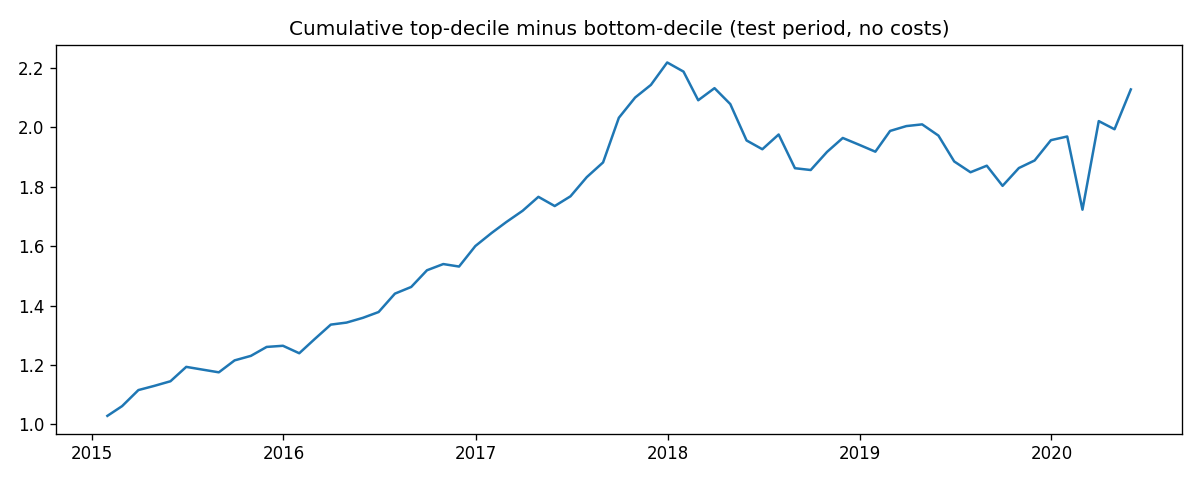

In [31]:
prediction(close, volume, mkt, OUT, split_year=2015)
show("06_decile_spread.png")